# Análise exploratória das tabelas brutas (`raw_rmi`)

O notebook tem duas partes para cada tabela:

- **Análise exploratória:** volume, valores únicos, nulos por coluna e as distribuições principais, para mostrar os padrões das bases.
- **Perfilamento:** compara a tabela com a documentação do desafio. Cada análise traz antes dela o resultado esperado e sustenta um achado da seção **Perfilamento** do [README](../README.md).

As seções 7 e 8 validam duas premissas da modelagem: o mapa turma → escola e a estabilidade do `id_aluno` dentro da `frequencia`.

**Como os dados são lidos:** as cinco tabelas da camada raw são baixadas uma vez do BigQuery por leitura direta (`list_rows`, sem consulta SQL) e guardadas em `notebooks/dados_raw/` (fora do Git). A partir daí, toda a análise é feita em pandas, e as execuções seguintes leem o cache local. Os resultados exibidos são sempre agregados.

**Para rodar:**

1. Carregue os dados brutos (`scripts/load_raw.ps1`, ver README).
2. Autentique: `gcloud auth application-default login`.
3. No ambiente do projeto: `pip install pandas pyarrow db-dtypes matplotlib google-cloud-bigquery-storage ipykernel`. O `google-cloud-bigquery-storage` acelera o download da `frequencia` (2,7 milhões de linhas).
4. Ajuste `PROJETO` na célula abaixo e execute todas as células.

Os dados são anonimizados e aleatorizados; os números descrevem a base entregue, não a rede real.

In [3]:
# Importações
from google.cloud import bigquery
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
# Variáveis Globais
PROJETO = "desafio-cientista-dados-peqc"  # ajuste para o seu projeto
DATASET = "raw_rmi"
TABELAS = ["aluno", "turma", "escola", "frequencia", "avaliacao"]

# Mapeamento das disciplinas 
DISCIPLINAS = {
    "disciplina_1": "Português",
    "disciplina_2": "Ciências",
    "disciplina_3": "Inglês",
    "disciplina_4": "Matemática",
}

In [5]:
# Instância do cliente BigQuery
cliente = bigquery.Client(project=PROJETO)

In [6]:
# Configuração do matplotlib
plt.rcParams.update({
    "figure.figsize": (8, 3.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [8]:
# Funções auxiliares
def carregar(tabela):
    """Lê a tabela inteira do BigQuery (leitura direta, sem consulta SQL)."""
    return cliente.list_rows(f"{PROJETO}.{DATASET}.{tabela}").to_dataframe()


def perfil_colunas(df):
    """Tipo, nulos (quantidade e % do total de linhas) e valores distintos de cada coluna."""
    return pd.DataFrame({
        "tipo_pandas": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "pct_nulos": (100 * df.isna().mean()).round(2),
        "distintos": df.nunique(),
    })


def ordenar_faixa_etaria(faixas):
    """Ordena as faixas pelo primeiro número ("6-10" antes de "11-14")."""
    return faixas.str.extract(r"(\d+)")[0].astype(float)


def pct(parte, total):
    """Percentual com uma casa decimal."""
    return round(100 * parte / total, 1)

In [9]:
# Carga das tabelas brutas
aluno = carregar("aluno")
turma = carregar("turma")
escola = carregar("escola")
frequencia = carregar("frequencia")
avaliacao = carregar("avaliacao")

## 1. Visão geral: linhas, colunas e tipos

### Linhas e colunas por tabela

Esperado: 
* aluno 97.044 linhas e 4 colunas; 
* turma 97.044 e 3; 
* escola 1.558 e 2; 
* frequencia 2.727.684 e 7; 
* avaliacao 221.687 e 8.

In [10]:
pd.DataFrame(
    {"qtd_linhas": [len(df) for df in (aluno, turma, escola, frequencia, avaliacao)],
     "qtd_colunas": [df.shape[1] for df in (aluno, turma, escola, frequencia, avaliacao)]},
    index=TABELAS,
)

,qtd_linhas,qtd_colunas
aluno,97044,4
turma,97044,3
escola,1558,2
frequencia,2727684,7
avaliacao,221687,8


### Tipos das colunas no BigQuery

Esperado: `id_aluno` é BYTES em todas as tabelas (a documentação diz STRING) e `avaliacao.bimestre` é STRING (a documentação diz INT64). Nenhuma tabela traz série, turno, tipo ou região.

In [11]:
pd.DataFrame(
    [(tabela, campo.name, campo.field_type)
     for tabela in TABELAS
     for campo in cliente.get_table(f"{PROJETO}.{DATASET}.{tabela}").schema],
    columns=["tabela", "coluna", "tipo_bigquery"],
)

,tabela,coluna,tipo_bigquery
0,aluno,id_aluno,BYTES
1,aluno,id_turma,INTEGER
2,aluno,faixa_etaria,STRING
3,aluno,bairro,INTEGER
4,turma,ano,INTEGER
5,turma,id_turma,INTEGER
6,turma,id_aluno,BYTES
7,escola,id_escola,INTEGER
8,escola,bairro,INTEGER
9,frequencia,id_escola,INTEGER


## 2. `aluno`

### Análise exploratória

In [12]:
pd.Series({
    "qtd_linhas": len(aluno),
    "qtd_alunos_unicos": aluno["id_aluno"].nunique(),
    "qtd_turmas": aluno["id_turma"].nunique(),
    "qtd_bairros_residencia": aluno["bairro"].nunique(),
})

qtd_linhas                97044
qtd_alunos_unicos         97044
qtd_turmas                17311
qtd_bairros_residencia     1069
dtype: int64

**Nulos e valores distintos por coluna.** Esperado: só `bairro` com nulos (68 linhas, 0,07%).

In [13]:
perfil_colunas(aluno)

,tipo_pandas,nulos,pct_nulos,distintos
id_aluno,object,0,0.00,97044
id_turma,Int64,0,0.00,17311
faixa_etaria,str,0,0.00,5
bairro,Int64,68,0.07,1069


**Alunos por faixa etária.** Esperado: 15–17 anos com 51,5% dos alunos. Essa distribuição parece improvável, tendo em vista que os dados são da rede municipal e o ensino médio é competência da rede estadual. Deixo como nota, porém por se tratar apenas de um desafio, não levarei essa consideração adiante

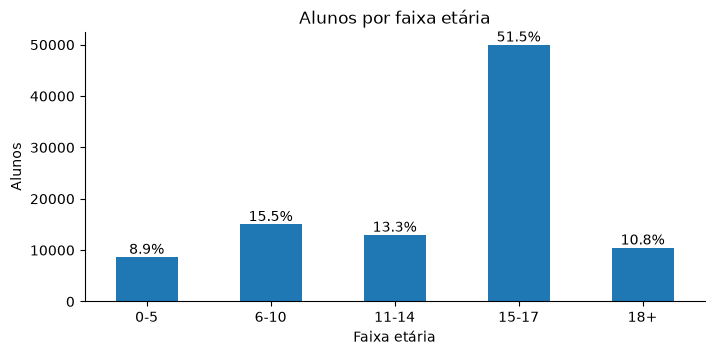

,faixa_etaria,qtd_alunos,pct
4,0-5,8640,8.9
1,6-10,15024,15.5
2,11-14,12947,13.3
0,15-17,49980,51.5
3,18+,10453,10.8


In [14]:
faixas = (
    aluno["faixa_etaria"].value_counts()
    .rename_axis("faixa_etaria").reset_index(name="qtd_alunos")
    .sort_values("faixa_etaria", key=ordenar_faixa_etaria)
)
faixas["pct"] = pct(faixas["qtd_alunos"], faixas["qtd_alunos"].sum())

ax = faixas.plot.bar(x="faixa_etaria", y="qtd_alunos", legend=False, rot=0)
ax.bar_label(ax.containers[0], labels=[f"{p}%" for p in faixas["pct"]])
ax.set(title="Alunos por faixa etária", xlabel="Faixa etária", ylabel="Alunos")
plt.show()
faixas

### Perfilamento

#### Granularidade

Esperado: uma linha por aluno (linhas = alunos distintos = 97.044).

In [18]:
pd.Series({"qtd_linhas": len(aluno), "qtd_alunos": aluno["id_aluno"].nunique()})

qtd_linhas    97044
qtd_alunos    97044
dtype: int64

## 3. `turma`

### Análise exploratória

**Nulos e valores distintos por coluna.**

In [19]:
perfil_colunas(turma)

,tipo_pandas,nulos,pct_nulos,distintos
ano,Int64,0,0.0,1
id_turma,Int64,0,0.0,17311
id_aluno,object,0,0.0,97044


**Tamanho das turmas.** Número de alunos por turma, pela tabela `turma` (uma linha por aluno).

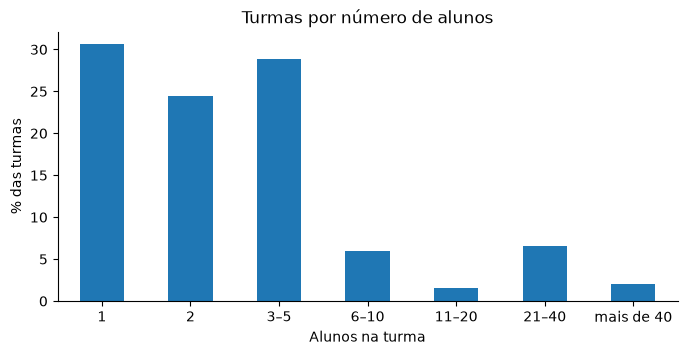

,qtd_turmas,qtd_alunos,pct_turmas,pct_alunos
1,5299,5299,30.6,5.5
2,4240,8480,24.5,8.7
3–5,4983,18084,28.8,18.6
6–10,1040,7386,6.0,7.6
11–20,261,3621,1.5,3.7
21–40,1149,39129,6.6,40.3
mais de 40,339,15045,2.0,15.5


In [21]:
tamanho = turma.groupby("id_turma").size()

faixas_tamanho = pd.cut(
    tamanho,
    bins=[0, 1, 2, 5, 10, 20, 40, tamanho.max()],
    labels=["1", "2", "3–5", "6–10", "11–20", "21–40", "mais de 40"],
)
resumo = pd.DataFrame({
    "qtd_turmas": tamanho.groupby(faixas_tamanho, observed=False).size(),
    "qtd_alunos": tamanho.groupby(faixas_tamanho, observed=False).sum(),
})
resumo["pct_turmas"] = pct(resumo["qtd_turmas"], resumo["qtd_turmas"].sum())
resumo["pct_alunos"] = pct(resumo["qtd_alunos"], resumo["qtd_alunos"].sum())

ax = resumo["pct_turmas"].plot.bar(rot=0)
ax.set(title="Turmas por número de alunos", xlabel="Alunos na turma", ylabel="% das turmas")
plt.show()
resumo

### Perfilamento

#### Granularidade e ano

Esperado: 97.044 linhas e 97.044 alunos distintos (uma linha por aluno, não por turma); `ano` com um único valor (2000).

In [22]:
pd.Series({
    "qtd_linhas": len(turma),
    "qtd_alunos": turma["id_aluno"].nunique(),
    "qtd_turmas": turma["id_turma"].nunique(),
    "qtd_anos": turma["ano"].nunique(),
    "ano": turma["ano"].min(),
})

qtd_linhas    97044
qtd_alunos    97044
qtd_turmas    17311
qtd_anos          1
ano            2000
dtype: int64

#### Mesma turma em `aluno` e `turma`

Esperado: 97.044 de 97.044 alunos (100%) com a mesma turma nas duas tabelas.

In [23]:
pares = aluno[["id_aluno", "id_turma"]].merge(
    turma[["id_aluno", "id_turma"]], on="id_aluno", suffixes=("_aluno", "_turma")
)
pd.Series({
    "qtd_alunos": len(pares),
    "qtd_mesma_turma": int((pares["id_turma_aluno"] == pares["id_turma_turma"]).sum()),
})

qtd_alunos         97044
qtd_mesma_turma    97044
dtype: int64

## 4. `escola` e bairros

### Análise exploratória

**Nulos e valores distintos por coluna.**

In [24]:
perfil_colunas(escola)

,tipo_pandas,nulos,pct_nulos,distintos
id_escola,Int64,0,0.0,1558
bairro,Int64,0,0.0,169


**Escolas por bairro.** Quantas escolas cada bairro tem, segundo a tabela `escola`.

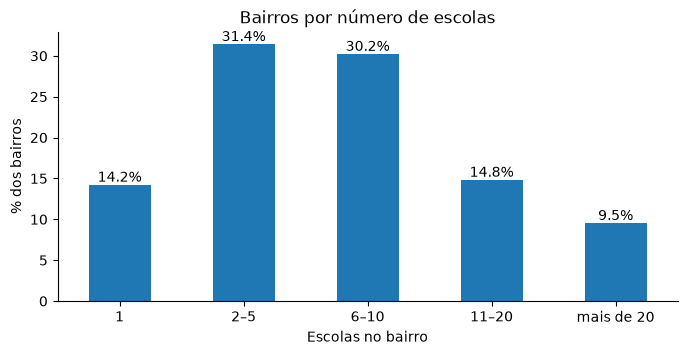

qtd_bairros                   169.0
mediana_escolas_por_bairro      6.0
maximo_escolas_por_bairro      98.0
dtype: float64

,qtd_bairros,qtd_escolas,pct_bairros,pct_escolas
count,,,,
1,24,24,14.2,1.5
2–5,53,169,31.4,10.8
6–10,51,375,30.2,24.1
11–20,25,352,14.8,22.6
mais de 20,16,638,9.5,40.9


In [28]:
escolas_por_bairro = escola["bairro"].astype("string").value_counts()

faixas_escolas = pd.cut(
    escolas_por_bairro,
    bins=[0, 1, 5, 10, 20, escolas_por_bairro.max()],
    labels=["1", "2–5", "6–10", "11–20", "mais de 20"],
)
resumo_bairros = pd.DataFrame({
    "qtd_bairros": escolas_por_bairro.groupby(faixas_escolas, observed=False).size(),
    "qtd_escolas": escolas_por_bairro.groupby(faixas_escolas, observed=False).sum(),
})

resumo_bairros["pct_bairros"] = pct(resumo_bairros["qtd_bairros"], resumo_bairros["qtd_bairros"].sum())
resumo_bairros["pct_escolas"] = pct(resumo_bairros["qtd_escolas"], resumo_bairros["qtd_escolas"].sum())

ax = resumo_bairros["pct_bairros"].plot.bar(rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set(title="Bairros por número de escolas", xlabel="Escolas no bairro", ylabel="% dos bairros")
plt.show()

display(pd.Series({
    "qtd_bairros": len(escolas_por_bairro),
    "mediana_escolas_por_bairro": escolas_por_bairro.median(),
    "maximo_escolas_por_bairro": escolas_por_bairro.max(),
}))
resumo_bairros

### Perfilamento

#### Escolas presentes na `frequencia`

Esperado: 1.558 escolas na tabela `escola`, das quais só 521 aparecem na `frequencia`, a única tabela com `id_escola` por registro.

In [29]:
pd.Series({
    "qtd_escolas": escola["id_escola"].nunique(),
    "qtd_escolas_na_frequencia": frequencia["id_escola"].nunique(),
})

qtd_escolas                  1558
qtd_escolas_na_frequencia     521
dtype: int64

#### Hashes de bairro de `aluno` e de `escola`

Esperado: nenhum valor em comum entre os dois hashes de bairro.

In [31]:
bairros_aluno = set(aluno["bairro"].dropna())
bairros_escola = set(escola["bairro"].dropna())
pd.Series({
    "qtd_bairros_aluno": len(bairros_aluno),
    "qtd_bairros_escola": len(bairros_escola),
    "qtd_em_comum": len(bairros_aluno & bairros_escola),
})

qtd_bairros_aluno     1069
qtd_bairros_escola     169
qtd_em_comum             0
dtype: int64

## 5. `frequencia`

### Análise exploratória

In [32]:
pd.Series({
    "qtd_linhas": len(frequencia),
    "qtd_alunos_unicos": frequencia["id_aluno"].nunique(),
    "qtd_turmas": frequencia["id_turma"].nunique(),
    "qtd_escolas": frequencia["id_escola"].nunique(),
    "qtd_disciplinas": frequencia["disciplina"].nunique(),
    "qtd_periodos": len(frequencia[["data_inicio", "data_fim"]].drop_duplicates()),
})

qtd_linhas           2727684
qtd_alunos_unicos      97044
qtd_turmas              5516
qtd_escolas              521
qtd_disciplinas            4
qtd_periodos              11
dtype: int64

**Nulos e valores distintos por coluna.**

In [33]:
perfil_colunas(frequencia)

,tipo_pandas,nulos,pct_nulos,distintos
id_escola,Int64,0,0.0,521
id_aluno,object,0,0.0,97044
id_turma,Int64,0,0.0,5516
data_inicio,str,0,0.0,11
data_fim,str,0,0.0,11
disciplina,str,0,0.0,4
frequencia,float64,0,0.0,137


**Alunos por período de apuração.** Mostra quantos alunos têm registro em cada período e a queda depois de julho.

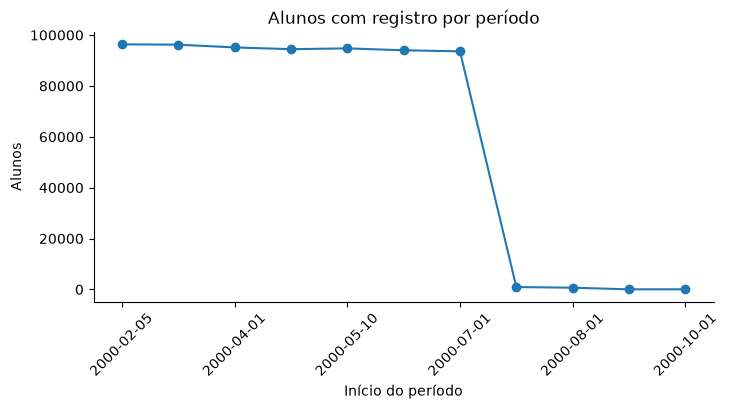

In [34]:
periodos = frequencia.groupby("data_inicio")["id_aluno"].nunique()

ax = periodos.plot(marker="o", rot=45)
ax.set(title="Alunos com registro por período", xlabel="Início do período", ylabel="Alunos")
plt.show()

**Distribuição dos valores de `frequencia`.** A linha tracejada marca 99, o menor valor possível pela regra de cálculo da fonte (ver o perfilamento abaixo). O eixo vertical está em escala logarítmica porque quase todos os registros estão perto de 100.

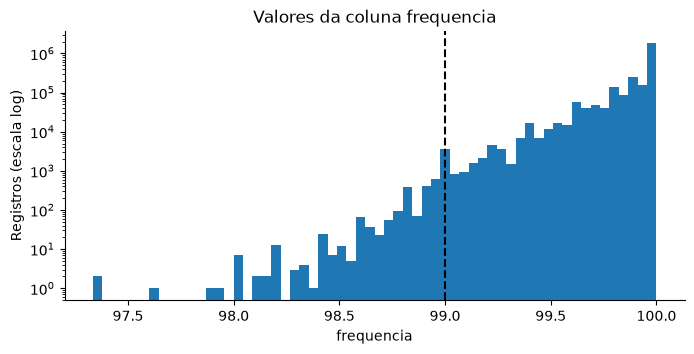

In [35]:
fig, ax = plt.subplots()
ax.hist(frequencia["frequencia"].dropna(), bins=60, log=True)
ax.axvline(99, color="black", linestyle="--")
ax.set(title="Valores da coluna frequencia", xlabel="frequencia", ylabel="Registros (escala log)")
plt.show()

**Faltas por disciplina.** Média simples de `100 − frequencia` (proporção dos dias letivos com falta) entre os registros de cada disciplina, só com os valores dentro da regra (99 a 100). É uma descrição dos registros, em que cada período pesa igual. O indicador do projeto pondera os períodos pela duração (ver `mart_educacao__absenteismo_disciplina`), e os valores podem diferir.

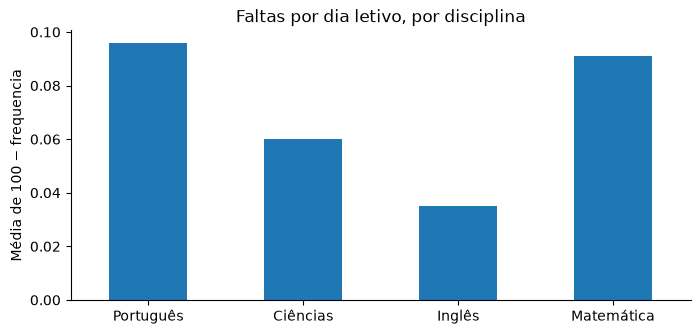

,qtd_registros,media_faltas_por_dia_letivo
disciplina,,
Português,680985,0.095788
Ciências,681890,0.060167
Inglês,681918,0.035047
Matemática,681034,0.091165


In [36]:
por_disciplina = (
    frequencia[frequencia["frequencia"] >= 99]
    .assign(faltas_por_dia_letivo=lambda df: 100 - df["frequencia"])
    .groupby("disciplina")
    .agg(qtd_registros=("frequencia", "size"), media_faltas_por_dia_letivo=("faltas_por_dia_letivo", "mean"))
    .rename(index=DISCIPLINAS)
)

ax = por_disciplina["media_faltas_por_dia_letivo"].plot.bar(rot=0)
ax.set(title="Faltas por dia letivo, por disciplina", xlabel="", ylabel="Média de 100 − frequencia")
plt.show()
por_disciplina

**Tamanho das escolas.** Alunos e turmas distintos por escola na `frequencia` (a única tabela que liga aluno e escola).

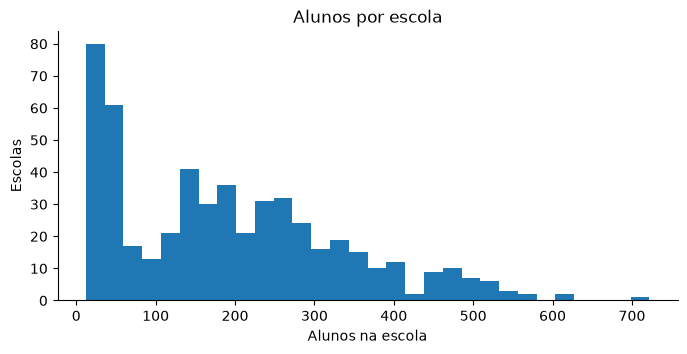

,qtd_alunos,qtd_turmas
count,521.0,521.0
mean,193.2,10.6
std,142.1,7.3
min,12.0,1.0
25%,57.0,3.0
50%,176.0,10.0
75%,277.0,15.0
max,722.0,39.0


In [37]:
por_escola = frequencia.groupby("id_escola").agg(
    qtd_alunos=("id_aluno", "nunique"), qtd_turmas=("id_turma", "nunique")
)

ax = por_escola["qtd_alunos"].plot.hist(bins=30)
ax.set(title="Alunos por escola", xlabel="Alunos na escola", ylabel="Escolas")
plt.show()
por_escola.describe().round(1)

### Perfilamento

#### Períodos de apuração

Esperado: 11 períodos, de 2000-02-05 a 2000-10-03; a partir de 2000-07-18, menos de 1% dos alunos.

In [38]:
frequencia.groupby(["data_inicio", "data_fim"]).agg(
    qtd_linhas=("id_aluno", "size"), qtd_alunos=("id_aluno", "nunique")
)

,,qtd_linhas,qtd_alunos
data_inicio,data_fim,,
2000-02-05,2000-02-28,398112,96350
2000-03-01,2000-03-31,397920,96213
2000-04-01,2000-04-30,386820,95139
2000-05-01,2000-05-09,379480,94441
2000-05-10,2000-05-31,399244,94761
2000-06-01,2000-06-30,383804,94014
2000-07-01,2000-07-17,375892,93589
2000-07-18,2000-07-31,3636,905
2000-08-01,2000-08-31,2640,654


#### Faixa de valores da coluna `frequencia`

Pela documentação, `frequencia = 100 - faltas / dias letivos`. Com as faltas entre 0 e o total de dias letivos, `faltas / dias` vai de 0 a 1 e o valor só pode ir de 99 a 100.

Esperado: mínimo de cerca de 97,3, máximo 100, e 1.857 registros (0,07%) abaixo de 99, o que indicaria mais faltas do que dias letivos.

In [39]:
valores = frequencia["frequencia"]
pd.Series({
    "minimo": valores.min(),
    "maximo": valores.max(),
    "qtd_abaixo_de_99": int((valores < 99).sum()),
    "pct_abaixo_de_99": round(100 * (valores < 99).mean(), 3),
})

minimo                97.333333
maximo               100.000000
qtd_abaixo_de_99    1857.000000
pct_abaixo_de_99       0.068000
dtype: float64

#### Linhas idênticas

Esperado: 1.483 linhas repetidas em todas as colunas.

In [40]:
frequencia_sem_identicas = frequencia.drop_duplicates()
len(frequencia) - len(frequencia_sem_identicas)

1483

#### Chaves com valores divergentes

Esperado: 1.093 chaves (aluno + turma + disciplina + período) com mais de um valor de frequência, depois de remover as linhas idênticas.

In [41]:
CHAVE = ["id_aluno", "id_turma", "disciplina", "data_inicio", "data_fim"]
linhas_por_chave = frequencia_sem_identicas.groupby(CHAVE).size()
int((linhas_por_chave > 1).sum())

1093

#### O `id_aluno` da `frequencia` corresponde ao de `aluno`?

Esperado: só 11 de 97.044 alunos têm a turma de `aluno` entre as suas turmas na `frequencia`. Se o vínculo aluno → turma fosse o mesmo, seriam quase todos.

In [42]:
turmas_na_frequencia = frequencia[["id_aluno", "id_turma"]].drop_duplicates()
cruzamento = aluno[["id_aluno", "id_turma"]].merge(
    turmas_na_frequencia, on=["id_aluno", "id_turma"], how="left", indicator=True
)
pd.Series({
    "qtd_alunos": len(cruzamento),
    "qtd_mesma_turma": int((cruzamento["_merge"] == "both").sum()),
})

qtd_alunos         97044
qtd_mesma_turma       11
dtype: int64

#### Frequência por aluno: `frequencia` × `avaliacao`

Segunda evidência sobre o `id_aluno`. Para cada aluno e bimestre, converte a `frequencia` em percentual (`100 × (1 − faltas/dias)`, ponderando os períodos pela duração) e compara com `avaliacao.frequencia`. Os bimestres 1 e 2 usam os cortes 2000-05-09 e 2000-07-17.

Esperado: correlação próxima de zero. Se as duas tabelas falassem do mesmo aluno, a correlação seria alta.

In [43]:
f = frequencia[(frequencia["data_fim"] <= "2000-07-17") & (frequencia["frequencia"] >= 99)].copy()
f["bimestre"] = np.where(f["data_fim"] <= "2000-05-09", 1, 2)
f["dias"] = (pd.to_datetime(f["data_fim"]) - pd.to_datetime(f["data_inicio"])).dt.days + 1
f["faltas"] = (100 - f["frequencia"]) * f["dias"]
pela_frequencia = f.groupby(["id_aluno", "bimestre"])[["faltas", "dias"]].sum()
pela_frequencia["percentual"] = 100 * (1 - pela_frequencia["faltas"] / pela_frequencia["dias"])

a = avaliacao.dropna(subset=["frequencia"]).copy()
a["bimestre"] = pd.to_numeric(a["bimestre"], errors="coerce")
a = a.dropna(subset=["bimestre"]).astype({"bimestre": int})
pela_avaliacao = a.groupby(["id_aluno", "bimestre"])["frequencia"].agg(["size", "first"])
pela_avaliacao = pela_avaliacao[pela_avaliacao["size"] == 1]  # uma linha por aluno e bimestre

pares = pela_avaliacao[["first"]].join(pela_frequencia[["percentual"]], how="inner")
pares.groupby(level="bimestre").apply(
    lambda g: pd.Series({"qtd_pares": len(g), "correlacao": round(g["first"].corr(g["percentual"]), 3)})
)

,qtd_pares,correlacao
bimestre,,
1,65650.0,0.004
2,56560.0,0.002


## 6. `avaliacao`

### Análise exploratória

In [44]:
pd.Series({
    "qtd_linhas": len(avaliacao),
    "qtd_alunos_unicos": avaliacao["id_aluno"].nunique(),
    "qtd_turmas": avaliacao["id_turma"].nunique(),
    "qtd_bimestres": avaliacao["bimestre"].nunique(),
})

qtd_linhas           221687
qtd_alunos_unicos     69502
qtd_turmas            11546
qtd_bimestres             4
dtype: int64

**Nulos e valores distintos por coluna.** Esperado: `disciplina_3` (Inglês) 100% nula, nenhuma nota preenchida.

In [45]:
perfil_colunas(avaliacao)

,tipo_pandas,nulos,pct_nulos,distintos
id_aluno,object,0,0.00,69502
id_turma,Int64,0,0.00,11546
frequencia,float64,1734,0.78,1901
bimestre,str,0,0.00,4
disciplina_1,float64,34609,15.61,1733
disciplina_2,float64,35931,16.21,1723
disciplina_3,float64,221687,100.00,0
disciplina_4,float64,35462,16.00,1739


**Linhas e alunos por bimestre.**

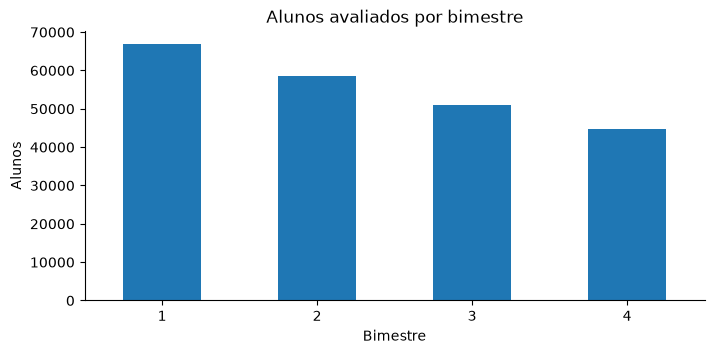

,qtd_linhas,qtd_alunos
bimestre,,
1,67089,66944
2,58931,58571
3,50960,50886
4,44707,44705


In [46]:
bimestres = avaliacao.groupby("bimestre").agg(
    qtd_linhas=("id_aluno", "size"), qtd_alunos=("id_aluno", "nunique")
)

ax = bimestres["qtd_alunos"].plot.bar(rot=0)
ax.set(title="Alunos avaliados por bimestre", xlabel="Bimestre", ylabel="Alunos")
plt.show()
bimestres

**Distribuição das notas por disciplina.** Inglês fica de fora por não ter nenhuma nota.

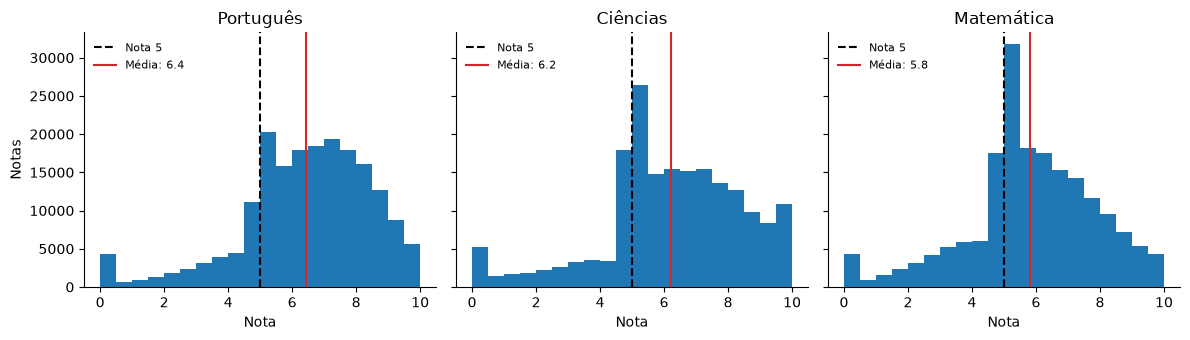

In [50]:
COM_NOTA = ["disciplina_1", "disciplina_2", "disciplina_4"]

fig, eixos = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, disciplina in zip(eixos, COM_NOTA):
    notas = avaliacao[disciplina].dropna()
    ax.hist(notas, bins=20, range=(0, 10))
    ax.axvline(5, color="black", linestyle="--", label="Nota 5")
    ax.axvline(notas.mean(), color="tab:red", label=f"Média: {notas.mean():.1f}")
    ax.set(title=DISCIPLINAS[disciplina], xlabel="Nota")
    ax.legend(loc="upper left", fontsize=8, frameon=False)
eixos[0].set_ylabel("Notas")
plt.tight_layout()
plt.show()

**Média das notas por bimestre e disciplina.**

In [48]:
avaliacao.groupby("bimestre")[COM_NOTA].mean().round(2).rename(columns=DISCIPLINAS)

,Português,Ciências,Matemática
bimestre,,,
1,5.92,5.79,5.41
2,6.38,6.08,5.55
3,6.60,6.33,6.00
4,6.94,6.78,6.41


**Frequência informada na avaliação.** Distribuição do percentual de frequência do bimestre (coluna `frequencia` da `avaliacao`, de 0 a 100).

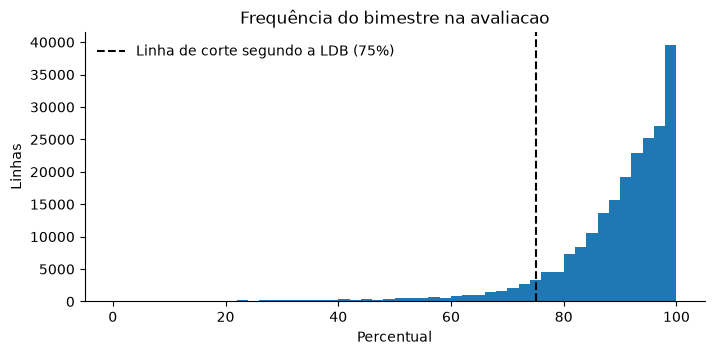

In [52]:
fig, ax = plt.subplots()
ax.hist(avaliacao["frequencia"].dropna(), bins=50, range=(0, 100))
ax.axvline(75, color="black", linestyle="--", label="Linha de corte segundo a LDB (75%)")
ax.set(title="Frequência do bimestre na avaliacao", xlabel="Percentual", ylabel="Linhas")
ax.legend(loc="upper left", frameon=False)
plt.show()

### Perfilamento

#### Granularidade

Esperado: 221.687 linhas, 221.106 pares aluno + bimestre (a chave do enunciado não é única: 569 pares repetidos) e 221.653 combinações aluno + turma + bimestre.

In [53]:
linhas_por_par = avaliacao.groupby(["id_aluno", "bimestre"], dropna=False).size()
pd.Series({
    "qtd_linhas": len(avaliacao),
    "qtd_pares_aluno_bimestre": len(linhas_por_par),
    "qtd_pares_repetidos": int((linhas_por_par > 1).sum()),
    "qtd_aluno_turma_bimestre": len(avaliacao[["id_aluno", "id_turma", "bimestre"]].drop_duplicates()),
})

qtd_linhas                  221687
qtd_pares_aluno_bimestre    221106
qtd_pares_repetidos            572
qtd_aluno_turma_bimestre    221653
dtype: int64

#### Chaves aluno + turma + bimestre duplicadas

Esperado: 31 chaves com mais de uma linha.

In [54]:
linhas_por_chave = avaliacao.groupby(["id_aluno", "id_turma", "bimestre"], dropna=False).size()
int((linhas_por_chave > 1).sum())

34

#### Aluno em mais de uma turma no mesmo bimestre

Esperado: 538 pares aluno + bimestre com duas ou mais turmas.

In [55]:
turmas_por_par = avaliacao.groupby(["id_aluno", "bimestre"], dropna=False)["id_turma"].nunique()
int((turmas_por_par > 1).sum())

538

#### Alunos sem nenhuma avaliação

Esperado: 27.542 dos 97.044 alunos de `aluno` (28%) sem nenhuma linha na `avaliacao`.

In [56]:
sem_avaliacao = ~aluno["id_aluno"].isin(set(avaliacao["id_aluno"]))
pd.Series({
    "qtd_alunos": len(aluno),
    "qtd_sem_avaliacao": int(sem_avaliacao.sum()),
    "pct_sem_avaliacao": pct(sem_avaliacao.sum(), len(aluno)),
})

qtd_alunos           97044.0
qtd_sem_avaliacao    27834.0
pct_sem_avaliacao       28.7
dtype: float64

## 7. Validação do mapa turma → escola

A `avaliacao` não tem escola. O projeto obtém a escola de cada nota pela turma, usando o par turma → escola da `frequencia`. Para verificar se esse vínculo se mantém entre as tabelas, a análise usa só a `avaliacao` para encontrar alunos que mudam de turma entre bimestres consecutivos e confere, pelo mapa, se as duas turmas ficam na mesma escola.

Entram só os pares aluno + bimestre com uma única turma, para que a mudança seja inequívoca.

### Mudanças de turma na mesma escola

Esperado: cerca de 67% em `pct_mesma_escola`.

In [57]:
mapa = frequencia[["id_turma", "id_escola"]].drop_duplicates()
assert mapa["id_turma"].is_unique, "uma turma em mais de uma escola: o mapa deixa de ser válido"
escola_da_turma = mapa.set_index("id_turma")["id_escola"]

a = avaliacao.assign(bimestre=pd.to_numeric(avaliacao["bimestre"], errors="coerce")).dropna(subset=["bimestre"])
turma_por_bimestre = a.groupby(["id_aluno", "bimestre"])["id_turma"].agg(["nunique", "first"])
turma_por_bimestre = (
    turma_por_bimestre[turma_por_bimestre["nunique"] == 1]["first"]
    .rename("id_turma").reset_index()
)

seguinte = turma_por_bimestre.assign(bimestre=turma_por_bimestre["bimestre"] - 1)
mudancas = turma_por_bimestre.merge(seguinte, on=["id_aluno", "bimestre"], suffixes=("_origem", "_destino"))
mudancas = mudancas[mudancas["id_turma_origem"] != mudancas["id_turma_destino"]]

escola_origem = mudancas["id_turma_origem"].map(escola_da_turma)
escola_destino = mudancas["id_turma_destino"].map(escola_da_turma)
com_as_duas = escola_origem.notna() & escola_destino.notna()
mesma_escola = com_as_duas & (escola_origem == escola_destino)

pd.Series({
    "qtd_mudancas": len(mudancas),
    "qtd_com_as_duas_escolas": int(com_as_duas.sum()),
    "qtd_mesma_escola": int(mesma_escola.sum()),
    "pct_mesma_escola": pct(mesma_escola.sum(), com_as_duas.sum()),
})

qtd_mudancas               5807.0
qtd_com_as_duas_escolas    4368.0
qtd_mesma_escola           2920.0
pct_mesma_escola             66.8
dtype: float64

### Referência ao acaso

Se o mapa fosse arbitrário, duas turmas sorteadas cairiam na mesma escola com probabilidade `Σ nₑ(nₑ − 1) / (N(N − 1))`, em que `nₑ` é o número de turmas da escola `e` e `N` o total de turmas. A conta usa a distribuição real de turmas por escola.

Esperado: valor muito abaixo de 1% (a estimativa do perfilamento era 0,05%).

In [58]:
turmas_por_escola = frequencia.groupby("id_escola")["id_turma"].nunique()
n, total = turmas_por_escola, turmas_por_escola.sum()
pd.Series({
    "qtd_turmas": total,
    "qtd_escolas": len(n),
    "pct_mesma_escola_ao_acaso": round(100 * (n * (n - 1)).sum() / (total * (total - 1)), 3),
})

qtd_turmas                   5516.000
qtd_escolas                   521.000
pct_mesma_escola_ao_acaso       0.266
dtype: float64

## 8. Estabilidade da identidade do aluno dentro da `frequencia`

O `id_aluno` da `frequencia` não corresponde ao das outras tabelas (seção 5). Os indicadores de absenteísmo somam, para cada `id_aluno`, os registros de vários períodos e disciplinas. Isso só faz sentido se, **dentro da `frequencia`**, o mesmo identificador acompanhar a mesma pessoa.

As análises abaixo não provam essa hipótese (sem a documentação da anonimização não há como confirmar), mas mostram se a estrutura interna é coerente com ela. Se os identificadores tivessem sido redistribuídos linha a linha, um mesmo `id_aluno` apareceria em várias turmas e escolas no mesmo período, e com disciplinas incompletas.

### Turmas e escolas por aluno no conjunto dos períodos

Esperado: a grande maioria dos alunos (o perfilamento registrou 91,6%) em uma única turma e uma única escola.

In [59]:
por_aluno = frequencia.groupby("id_aluno").agg(
    qtd_turmas=("id_turma", "nunique"), qtd_escolas=("id_escola", "nunique")
)
pd.Series({
    "qtd_alunos": len(por_aluno),
    "pct_uma_turma_uma_escola": pct(((por_aluno["qtd_turmas"] == 1) & (por_aluno["qtd_escolas"] == 1)).sum(), len(por_aluno)),
    "pct_mais_de_uma_escola": pct((por_aluno["qtd_escolas"] > 1).sum(), len(por_aluno)),
})

qtd_alunos                  97044.0
pct_uma_turma_uma_escola       91.6
pct_mais_de_uma_escola          3.6
dtype: float64

### Coerência dentro de cada período

Esperado, se a identidade for estável: quase todos os pares aluno + período em uma só turma e com as quatro disciplinas.

In [60]:
por_periodo = frequencia.groupby(["id_aluno", "data_inicio", "data_fim"]).agg(
    qtd_turmas=("id_turma", "nunique"), qtd_disciplinas=("disciplina", "nunique")
)
pd.Series({
    "qtd_pares_aluno_periodo": len(por_periodo),
    "pct_uma_turma_no_periodo": pct((por_periodo["qtd_turmas"] == 1).sum(), len(por_periodo)),
    "pct_quatro_disciplinas": pct((por_periodo["qtd_disciplinas"] == 4).sum(), len(por_periodo)),
})

qtd_pares_aluno_periodo     666100.0
pct_uma_turma_no_periodo        97.8
pct_quatro_disciplinas         100.0
dtype: float64

### Continuidade entre períodos consecutivos

Esperado, se a identidade for estável: na maioria das passagens de um período para o seguinte, o aluno continua na mesma turma.

In [61]:
turma_por_periodo = frequencia.groupby(["id_aluno", "data_inicio"])["id_turma"].agg(["nunique", "first"])
turma_por_periodo = (
    turma_por_periodo[turma_por_periodo["nunique"] == 1]["first"]
    .rename("id_turma").reset_index()
    .sort_values(["id_aluno", "data_inicio"])
)
turma_por_periodo["id_turma_anterior"] = turma_por_periodo.groupby("id_aluno")["id_turma"].shift()
passagens = turma_por_periodo.dropna(subset=["id_turma_anterior"])
pd.Series({
    "qtd_passagens": len(passagens),
    "pct_mesma_turma": pct((passagens["id_turma"] == passagens["id_turma_anterior"]).sum(), len(passagens)),
})

qtd_passagens      554244.0
pct_mesma_turma        99.1
dtype: float64

**Como ler:** proporções altas nas três análises são compatíveis com uma identidade estável dentro da tabela. Proporções baixas indicariam identificadores redistribuídos por linha, e a frequência por aluno perderia sentido. Mesmo com resultados altos, a conclusão é uma hipótese plausível, registrada como tal no README.